# LAB 1 — Collaborative Filtering บน MovieMini-12: จากเมทริกซ์คะแนน → หลายโมเดล → Offline Evaluation → GUI

Lab นี้แสดง **แนวทางการสร้าง Recommender แบบการกรองร่วม (Collaborative Filtering)** ตามเนื้อหาบทที่ 5
โดยใช้ข้อมูลภาพยนตร์ MovieMini-12 ชุดเดียวกับบทที่ 3–4 (ผู้ใช้ 8 คน ภาพยนตร์ 12 เรื่อง คะแนน 32 ค่า)
แต่ **ไม่ใช้เนื้อหาของภาพยนตร์เลย** ใช้เพียงพฤติกรรมของผู้ใช้ทุกคน

| Part | เนื้อหา | หัวข้อในบทที่ 5 |
|---|---|---|
| 0 | Environment + Dataset + เมทริกซ์คะแนน | 5.2 |
| 1 | สถิติพื้นฐานของเมทริกซ์ + Heatmap | 5.2.2 |
| 2 | Core Functions: ความคล้าย, 13 โมเดล, Metric | 5.4–5.13, บทที่ 2 |
| 3 | ตัวอย่าง u1: ความคล้าย + ค่าทำนายของทุกโมเดล | 5.4–5.12 |
| 4 | ออกแบบการทดลองแบบ Offline (Protocol Card + Validation Split) | 5.14, 5.16 |
| 5 | การทดลองที่ 1 — Rating Prediction (Leave-One-Rating-Out) | 5.14.1 |
| 6 | การทดลองที่ 2 — Ranking (Leave-One-Liked-Out + ค่าคาดหมายเมื่อคะแนนเสมอ) | 5.14.2 |
| 7 | การทดลองที่ 3 — Beyond-Accuracy | บทที่ 2 |
| 8 | ตัวอย่าง Output บน Validation Dataset: เทียบ Rating และ Ranking ทุกโมเดล | 5.14 |
| 9 | ตารางสรุป + Chart | 5.14 |
| 10 | การทดลองเสริม: Sensitivity ของไฮเพอร์พารามิเตอร์, เมล็ดสุ่ม, Paired Bootstrap | 5.9.3, 5.17 |
| 11 | GUI (Gradio): ข้อมูลผู้ใช้ + รายการแนะนำ + เทียบโมเดล | 5.16 |

> ไม่มีแบบฝึกหัดใน Lab นี้ แต่ใน code มี comment เพื่อชี้ประเด็นสำคัญให้ผู้เรียนสังเกต

In [1]:
# ============================================================
# Part 0 — Environment & Dataset
# ============================================================
!pip -q install gradio

import math, random, warnings, itertools, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
SEED = 2569                     # เมล็ดสุ่มเดียวกับในบทที่ 5

# ------------------------------------------------------------
# 0.1 พยายามอ่าน Dataset จาก Google Drive (ชุดเดียวกับ LAB บทที่ 3–4)
#     ถ้าไม่พบ จะใช้ MovieMini-12 ที่ฝังไว้ใน code (ตารางที่ 5.3)
# ------------------------------------------------------------
DATA_DIR = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/Colab Notebooks")
    DATA_ROOT = BASE / "Dataset_Chapter3_4"
    DATA_DIR = DATA_ROOT / "data" if (DATA_ROOT / "data").exists() else DATA_ROOT
except Exception as e:
    print("ไม่ได้รันบน Colab หรือ mount Drive ไม่ได้ → ใช้ข้อมูลที่ฝังไว้", type(e).__name__)

BUILTIN_ITEMS = pd.DataFrame({
    "item_id": [f"i{k}" for k in range(1, 13)],
    "title": ["Toy Story 5", "Inside Out 2", "The Wild Robot", "It Ends with Us", "Wicked",
              "Bridget Jones: Mad About the Boy", "Ballerina", "Furiosa: A Mad Max Saga",
              "Conclave", "Dune: Part Two", "Mickey 17", "Project Hail Mary"],
    "genre": ["Animation|Family", "Animation|Family", "Animation|Sci-Fi", "Drama|Romance",
              "Fantasy|Musical", "Drama|Romance", "Action|Thriller", "Action|Sci-Fi",
              "Drama|Thriller", "Action|Sci-Fi", "Sci-Fi|Thriller", "Drama|Sci-Fi"]})
BUILTIN_RATINGS = pd.DataFrame(
    [("u1","i1",5),("u1","i2",5),("u1","i3",4),("u1","i4",1),("u1","i6",1),
     ("u2","i1",2),("u2","i4",5),("u2","i5",4),("u2","i6",5),
     ("u3","i7",1),("u3","i10",5),("u3","i11",5),("u3","i12",4),
     ("u4","i1",4),("u4","i5",1),("u4","i7",5),("u4","i8",5),
     ("u5","i3",4),("u5","i6",3),("u5","i9",5),("u5","i10",2),
     ("u6","i2",5),("u6","i5",4),("u6","i11",3),
     ("u7","i3",3),("u7","i8",2),("u7","i11",4),("u7","i12",5),
     ("u8","i2",2),("u8","i4",4),("u8","i6",5),("u8","i11",3)],
    columns=["user_id","item_id","rating"])

def load_dataset():
    if DATA_DIR is not None and (DATA_DIR / "metadata.csv").exists() and (DATA_DIR / "ratings.csv").exists():
        items = pd.read_csv(DATA_DIR / "metadata.csv")
        ratings = pd.read_csv(DATA_DIR / "ratings.csv")
        for old, new in {"movie_id":"item_id","id":"item_id","movie_title":"title","name":"title",
                         "genres":"genre"}.items():
            if old in items.columns and new not in items.columns:
                items = items.rename(columns={old:new})
        for old, new in {"uid":"user_id","user":"user_id","iid":"item_id","movie_id":"item_id",
                         "score":"rating"}.items():
            if old in ratings.columns and new not in ratings.columns:
                ratings = ratings.rename(columns={old:new})
        print("อ่านข้อมูลจาก", DATA_DIR)
        return items, ratings, "Drive"
    print("ใช้ MovieMini-12 ที่ฝังไว้ (ตารางที่ 5.3)")
    return BUILTIN_ITEMS.copy(), BUILTIN_RATINGS.copy(), "Built-in"

items, ratings, DATA_SOURCE = load_dataset()
items["item_id"] = items["item_id"].astype(str)
items["genre"] = items["genre"].fillna("").astype(str).str.replace(",", "|")
ratings["user_id"] = ratings["user_id"].astype(str)
ratings["item_id"] = ratings["item_id"].astype(str)
ratings["rating"] = pd.to_numeric(ratings["rating"]).astype(float)

# จัดลำดับรหัสแบบธรรมชาติ (i2 มาก่อน i10) เพื่อให้ตรงกับตารางในหนังสือ
def natural_key(s):
    digits = "".join(ch for ch in str(s) if ch.isdigit())
    return (int(digits) if digits else 0, str(s))

USERS = sorted(ratings["user_id"].unique(), key=natural_key)
ITEMS = sorted(items["item_id"].unique(), key=natural_key)
items = items.set_index("item_id").loc[ITEMS].reset_index()
U_INDEX = {u:k for k, u in enumerate(USERS)}
I_INDEX = {i:k for k, i in enumerate(ITEMS)}
TITLE = dict(zip(items["item_id"], items["title"]))
GENRE = dict(zip(items["item_id"], items["genre"]))

# ------------------------------------------------------------
# 0.2 เมทริกซ์ผู้ใช้–รายการ R: ช่องว่าง = NaN (ไม่รู้) ไม่ใช่ศูนย์
# ------------------------------------------------------------
def build_matrix(df):
    R = np.full((len(USERS), len(ITEMS)), np.nan)
    for u, i, r in df[["user_id","item_id","rating"]].itertuples(index=False):
        R[U_INDEX[u], I_INDEX[i]] = r
    return R

R_FULL = build_matrix(ratings)
LIKE_T = 4.0                    # กติกาเดียวกับบทที่ 3–4: คะแนน 4–5 = "ชอบ"

# เวกเตอร์แนวภาพยนตร์ ใช้ "วัด" ILD และ Calibration เท่านั้น (ไม่ได้ใช้ในการแนะนำ)
ALL_GENRES = sorted({g for s in items["genre"] for g in s.split("|") if g})
G_MAT = np.array([[1.0 if g in GENRE[i].split("|") else 0.0 for g in ALL_GENRES] for i in ITEMS])

print(f"Source={DATA_SOURCE}  Users={len(USERS)}  Items={len(ITEMS)}  Ratings={int((~np.isnan(R_FULL)).sum())}")
display(pd.DataFrame(R_FULL, index=USERS, columns=ITEMS).fillna("·"))
display(items)

Mounted at /content/drive
อ่านข้อมูลจาก /content/drive/MyDrive/Colab Notebooks/Dataset_Chapter3_4/data
Source=Drive  Users=8  Items=12  Ratings=32


,i1,i2,i3,i4,i5,i6,i7,i8,i9,i10,i11,i12
u1,5.0,5.0,4.0,1.0,·,1.0,·,·,·,·,·,·
u2,2.0,·,·,5.0,4.0,5.0,·,·,·,·,·,·
u3,·,·,·,·,·,·,1.0,·,·,5.0,5.0,4.0
u4,4.0,·,·,·,1.0,·,5.0,5.0,·,·,·,·
u5,·,·,4.0,·,·,3.0,·,·,5.0,2.0,·,·
u6,·,5.0,·,·,4.0,·,·,·,·,·,3.0,·
u7,·,·,3.0,·,·,·,·,2.0,·,·,4.0,5.0
u8,·,2.0,·,4.0,·,5.0,·,·,·,·,3.0,·


,item_id,title,year,genre,image_brightness,image_warm,image_cartoon,audio_energy,audio_melody,audio_dark,video_change,video_cuts,video_animation,synopsis
0,i1,Toy Story 5,2026,Animation|Family,0.9,0.6,0.9,0.5,0.7,0.1,0.6,0.5,1.0,A cowboy toy and a space ranger toy lead the t...
1,i2,Inside Out 2,2024,Animation|Family,0.8,0.8,0.9,0.5,1.0,0.2,0.5,0.4,1.0,"Inside the mind of a teenage girl, five emotio..."
2,i3,The Wild Robot,2024,Animation|Sci-Fi,0.7,0.5,0.8,0.3,0.8,0.4,0.4,0.3,1.0,A shipwrecked robot boots up on a wild island ...
3,i4,It Ends with Us,2024,Drama|Romance,0.5,0.7,0.2,0.3,0.8,0.3,0.4,0.3,0.0,A florist falls in love with a charming surgeo...
4,i5,Wicked,2024,Fantasy|Musical,0.7,0.6,0.5,0.4,1.0,0.1,0.3,0.4,0.0,A green-skinned woman with a gift for magic jo...
5,i6,Bridget Jones: Mad About the Boy,2025,Drama|Romance,0.6,0.8,0.3,0.2,0.8,0.1,0.2,0.2,0.0,A widowed mother of two children keeps talking...
6,i7,Ballerina,2025,Action|Thriller,0.2,0.3,0.1,0.9,0.2,0.8,0.9,0.9,0.0,A ballerina trained as an assassin by a secret...
7,i8,Furiosa: A Mad Max Saga,2024,Action|Sci-Fi,0.6,0.9,0.3,1.0,0.3,0.7,1.0,1.0,0.0,"Snatched from a fertile place as a child, a su..."
8,i9,Conclave,2024,Drama|Thriller,0.4,0.3,0.1,0.3,0.5,0.6,0.3,0.4,0.0,"After the death of the pope, a cardinal must r..."
9,i10,Dune: Part Two,2024,Action|Sci-Fi,0.5,0.8,0.1,0.8,0.3,0.8,0.7,0.6,0.0,"On a desert planet, a young heir of a fallen d..."


## Part 1 — สถิติพื้นฐานของเมทริกซ์คะแนน (หัวข้อ 5.2.2)
ตัวเลขสี่กลุ่มที่ต้องดูเสมอก่อนสร้างแบบจำลอง: **ความหนาแน่น, ค่าเฉลี่ยรายผู้ใช้, จำนวนคะแนนต่อรายการ, จำนวนรายการร่วมระหว่างผู้ใช้**

,ค่า
ความหนาแน่น (density),0.3333
ค่าเฉลี่ยรวม (mu),3.6250
รายการร่วมเฉลี่ยต่อคู่ผู้ใช้,1.1071
คู่ผู้ใช้ที่ไม่มีรายการร่วมเลย,6.0000
จำนวนคู่ชอบ (rating>=4),20.0000


,u1,u2,u3,u4,u5,u6,u7,u8
ค่าเฉลี่ยผู้ใช้,3.2,4.0,3.75,3.75,3.5,4.0,3.5,3.5
จำนวนคะแนน,5.0,4.0,4.00,4.00,4.0,3.0,4.0,4.0


,i1,i2,i3,i4,i5,i6,i7,i8,i9,i10,i11,i12
จำนวนคะแนน,3,3,3,3,3,4,2,2,1,2,4,2
จำนวนผู้ชอบ,2,2,2,2,2,2,1,1,1,1,2,2


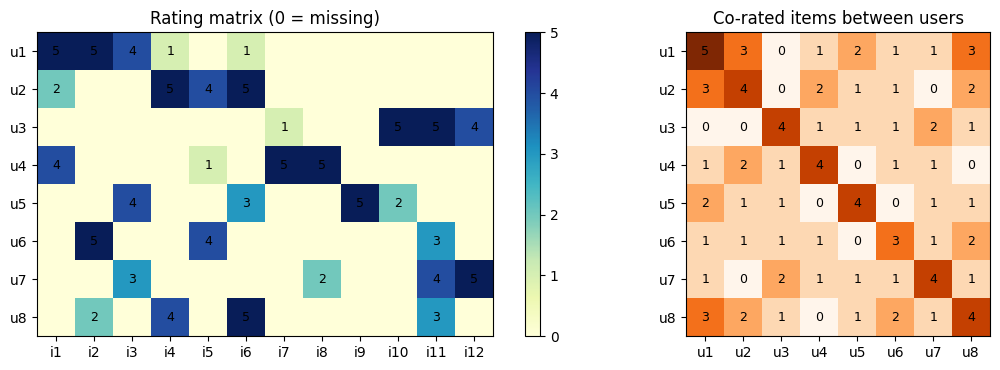

In [2]:
known = ~np.isnan(R_FULL)
co_rated = np.array([[int((known[a] & known[b]).sum()) for b in range(len(USERS))] for a in range(len(USERS))])
pairs = [co_rated[a, b] for a, b in itertools.combinations(range(len(USERS)), 2)]

stats = pd.Series({
    "ความหนาแน่น (density)": known.sum() / R_FULL.size,
    "ค่าเฉลี่ยรวม (mu)": np.nanmean(R_FULL),
    "รายการร่วมเฉลี่ยต่อคู่ผู้ใช้": np.mean(pairs),
    "คู่ผู้ใช้ที่ไม่มีรายการร่วมเลย": int(np.sum(np.array(pairs) == 0)),
    "จำนวนคู่ชอบ (rating>=4)": int((np.nan_to_num(R_FULL) >= LIKE_T).sum()),
})
display(stats.round(4).to_frame("ค่า"))
display(pd.DataFrame({"ค่าเฉลี่ยผู้ใช้": np.nanmean(R_FULL, axis=1).round(2),
                      "จำนวนคะแนน": known.sum(axis=1)}, index=USERS).T)
display(pd.DataFrame({"จำนวนคะแนน": known.sum(axis=0),
                      "จำนวนผู้ชอบ": (np.nan_to_num(R_FULL) >= LIKE_T).sum(axis=0)}, index=ITEMS).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
im = ax[0].imshow(np.nan_to_num(R_FULL, nan=0), cmap="YlGnBu", vmin=0, vmax=5)
ax[0].set_xticks(range(len(ITEMS))); ax[0].set_xticklabels(ITEMS)
ax[0].set_yticks(range(len(USERS))); ax[0].set_yticklabels(USERS)
for a in range(len(USERS)):
    for b in range(len(ITEMS)):
        if known[a, b]: ax[0].text(b, a, int(R_FULL[a, b]), ha="center", va="center", fontsize=9)
ax[0].set_title("Rating matrix (0 = missing)")
fig.colorbar(im, ax=ax[0], fraction=0.03)
ax[1].imshow(co_rated, cmap="Oranges")
for a in range(len(USERS)):
    for b in range(len(USERS)):
        ax[1].text(b, a, co_rated[a, b], ha="center", va="center", fontsize=9)
ax[1].set_xticks(range(len(USERS))); ax[1].set_xticklabels(USERS)
ax[1].set_yticks(range(len(USERS))); ax[1].set_yticklabels(USERS)
ax[1].set_title("Co-rated items between users")
plt.tight_layout(); plt.show()
# สังเกต: ความหนาแน่น 33% แต่คู่ผู้ใช้ส่วนใหญ่มีรายการร่วมเพียง 0–1 เรื่อง → ความคล้ายจากหลักฐานน้อย

## Part 2 — Core Functions
รวมทุกฟังก์ชันที่ Part 3–11 เรียกใช้ไว้ใน cell เดียว
- **ความคล้าย**: Pearson, Cosine, Adjusted Cosine, Jaccard + Significance Weighting / Shrinkage (5.4)
- **13 โมเดล** ที่มี interface เดียวกัน `fit(R)` → `predict(u, i)` (คะแนน 1–5) และ `scores(u)` (คะแนนจัดอันดับ)
- **Metric**: RMSE/MAE, Precision/Recall/F1/HR/MRR/MAP/nDCG/AUC แบบค่าคาดหมายเมื่อคะแนนเสมอ (สมการ 5.14) และ Beyond-Accuracy

In [3]:
# ============================================================
# Core Functions — Similarity + Models + Metrics
# ============================================================

# ---------- 2.1 Similarity (หัวข้อ 5.4) ----------
def pearson_users(R, a, b):
    """Pearson บนรายการร่วม ใช้ค่าเฉลี่ยของผู้ใช้จากทุกคะแนนของผู้ใช้ (ตามบทที่ 5)"""
    kn = ~np.isnan(R); co = kn[a] & kn[b]
    if co.sum() == 0: return 0.0, 0
    x = R[a, co] - np.nanmean(R[a]); y = R[b, co] - np.nanmean(R[b])
    den = np.sqrt((x**2).sum() * (y**2).sum())
    return (float((x*y).sum() / den) if den else 0.0), int(co.sum())

def cosine_users(R, a, b):
    x, y = np.nan_to_num(R[a]), np.nan_to_num(R[b])
    den = np.linalg.norm(x) * np.linalg.norm(y)
    return float(x @ y / den) if den else 0.0

def jaccard_users(R, a, b):
    kn = ~np.isnan(R)
    union = (kn[a] | kn[b]).sum()
    return float((kn[a] & kn[b]).sum() / union) if union else 0.0

def adjusted_cosine_items(R, i, j):
    """Adjusted Cosine (Sarwar et al.): ลบค่าเฉลี่ยของ 'ผู้ใช้' ก่อนวัดมุมระหว่างรายการ"""
    kn = ~np.isnan(R); co = kn[:, i] & kn[:, j]
    if co.sum() == 0: return 0.0
    mu_u = np.nanmean(R, axis=1)
    x = R[co, i] - mu_u[co]; y = R[co, j] - mu_u[co]
    den = np.sqrt((x**2).sum() * (y**2).sum())
    return float((x*y).sum() / den) if den else 0.0

def significance_weight(s, n, beta=3):   # Herlocker: s * min(n, beta)/beta
    return s * min(n, beta) / beta

def shrink(s, n, lam=2):                 # Koren: s * n/(n + lambda)
    return s * n / (n + lam)

# ---------- 2.2 Models: interface เดียวกันทุกตัว ----------
class Recommender:
    name = "Base"; family = "-"; rating_model = True
    def fit(self, R):
        self.R = R.copy(); self.kn = ~np.isnan(R)
        self.mu = float(np.nanmean(R))
        with np.errstate(all="ignore"):
            self.mu_u = np.where(self.kn.sum(1) > 0, np.nanmean(np.where(self.kn, R, np.nan), axis=1), self.mu)
        self._fit(); return self
    def _fit(self): pass
    def predict(self, u, i):                # คะแนนทำนาย (ตัดให้อยู่ใน 1–5)
        return float(np.clip(self._predict(u, i), 1, 5)) if self.rating_model else np.nan
    def _predict(self, u, i): raise NotImplementedError
    def scores(self, u):                    # คะแนนสำหรับจัดอันดับทุกรายการ
        return np.array([self.predict(u, i) for i in range(self.R.shape[1])])
    def explain(self, u, i): return ""

class GlobalMean(Recommender):
    name, family = "GlobalMean", "Baseline"
    def _predict(self, u, i): return self.mu

class UserMean(Recommender):
    name, family = "UserMean", "Baseline"
    def _predict(self, u, i): return self.mu_u[u]

class ItemMean(Recommender):
    name, family = "ItemMean", "Baseline"
    def _fit(self):
        cnt = self.kn.sum(0)
        with np.errstate(all="ignore"):
            self.mu_i = np.where(cnt > 0, np.nansum(np.nan_to_num(self.R), 0) / np.maximum(cnt, 1), self.mu)
    def _predict(self, u, i): return self.mu_i[i]

class Popularity(Recommender):
    """จำนวนผู้ชอบ (rating>=4) — ไม่ทำนายคะแนน ใช้จัดอันดับอย่างเดียว"""
    name, family, rating_model = "Popularity", "Baseline", False
    def _fit(self): self.pop = (np.nan_to_num(self.R) >= LIKE_T).sum(0).astype(float)
    def scores(self, u): return self.pop.copy()

class BiasBaseline(Recommender):
    """สมการ 5.7: b_i ก่อน แล้ว b_u พร้อมการหด lam_i, lam_u"""
    name, family = "Baseline(bias)", "Model-based"
    def __init__(self, lam_i=2.0, lam_u=2.0): self.lam_i, self.lam_u = lam_i, lam_u
    def _fit(self):
        R, kn, mu = self.R, self.kn, self.mu
        self.b_i = np.array([(R[kn[:, i], i] - mu).sum() / (self.lam_i + kn[:, i].sum()) for i in range(R.shape[1])])
        self.b_u = np.array([(R[u, kn[u]] - mu - self.b_i[kn[u]]).sum() / (self.lam_u + kn[u].sum()) for u in range(R.shape[0])])
    def _predict(self, u, i): return self.mu + self.b_u[u] + self.b_i[i]

class UserKNN(Recommender):
    """สมการ 5.4: ยืมส่วนเบี่ยงเบนจากเพื่อนบ้านเชิงบวกไม่เกิน k คน"""
    name, family = "User-kNN", "Memory-based"
    def __init__(self, k=3, weighting=None, beta=3, lam=2, name=None):
        self.k, self.weighting, self.beta, self.lam = k, weighting, beta, lam
        if name: self.name = name
    def _fit(self):
        n = self.R.shape[0]; self.S = np.zeros((n, n))
        for a in range(n):
            for b in range(n):
                if a == b: continue
                s, c = pearson_users(self.R, a, b)
                if self.weighting == "significance": s = significance_weight(s, c, self.beta)
                if self.weighting == "shrinkage": s = shrink(s, c, self.lam)
                self.S[a, b] = s
    def neighbors(self, u, i):
        nb = [(self.S[u, v], v) for v in range(self.R.shape[0]) if v != u and self.kn[v, i] and self.S[u, v] > 0]
        return sorted(nb, reverse=True)[:self.k]
    def _predict(self, u, i):
        nb = self.neighbors(u, i)
        if not nb: return self.mu_u[u]                 # ไม่มีหลักฐาน → ค่าเฉลี่ยของผู้ใช้
        num = sum(s * (self.R[v, i] - self.mu_u[v]) for s, v in nb)
        return self.mu_u[u] + num / sum(abs(s) for s, v in nb)
    def explain(self, u, i):
        return ", ".join(f"{USERS[v]}({s:.2f})" for s, v in self.neighbors(u, i)) or "— (ใช้ค่าเฉลี่ยผู้ใช้)"

class ItemKNN(Recommender):
    """สมการ 5.6: ค่าเฉลี่ยถ่วงน้ำหนักของคะแนนผู้ใช้เองต่อรายการที่คล้ายเชิงบวก"""
    name, family = "Item-kNN", "Memory-based"
    def __init__(self, k=3): self.k = k
    def _fit(self):
        m = self.R.shape[1]; self.S = np.zeros((m, m))
        for i in range(m):
            for j in range(m):
                if i != j: self.S[i, j] = adjusted_cosine_items(self.R, i, j)
    def neighbors(self, u, i):
        nb = [(self.S[i, j], j) for j in range(self.R.shape[1]) if j != i and self.kn[u, j] and self.S[i, j] > 0]
        return sorted(nb, reverse=True)[:self.k]
    def _predict(self, u, i):
        nb = self.neighbors(u, i)
        if not nb: return self.mu_u[u]
        return sum(s * self.R[u, j] for s, j in nb) / sum(s for s, j in nb)
    def explain(self, u, i):
        return ", ".join(f"{ITEMS[j]}({s:.2f})" for s, j in self.neighbors(u, i)) or "— (ใช้ค่าเฉลี่ยผู้ใช้)"

class UserKNNImplicit(Recommender):
    """สมการ 5.5: Cosine บนเวกเตอร์ชอบ 0/1 แล้วรวมความคล้ายของเพื่อนบ้านที่ชอบรายการ"""
    name, family, rating_model = "User-kNN(implicit)", "Memory-based", False
    def __init__(self, k=3): self.k = k
    def _fit(self):
        X = (np.nan_to_num(self.R) >= LIKE_T).astype(float)
        nrm = np.linalg.norm(X, axis=1, keepdims=True); nrm[nrm == 0] = 1
        S = (X / nrm) @ (X / nrm).T; np.fill_diagonal(S, 0)
        self.X, self.S = X, S
    def scores(self, u):
        top = np.argsort(-self.S[u])[:self.k]
        return self.S[u, top] @ self.X[top]

class MF_SGD(Recommender):
    """สมการ 5.8–5.9: MF + bias ฝึกด้วย SGD"""
    name, family = "MF-SGD", "Latent factor"
    def __init__(self, k=2, lr=0.05, reg=0.5, epochs=150, seed=SEED):
        self.k, self.lr, self.reg, self.epochs, self.seed = k, lr, reg, epochs, seed
    def _fit(self):
        rng = np.random.default_rng(self.seed); nU, nI = self.R.shape
        self.P = rng.normal(0, 0.1, (nU, self.k)); self.Q = rng.normal(0, 0.1, (nI, self.k))
        self.bu = np.zeros(nU); self.bi = np.zeros(nI)
        obs = list(zip(*np.where(self.kn))); self.history = []
        for ep in range(self.epochs):
            for t in rng.permutation(len(obs)):
                u, i = obs[t]; r = self.R[u, i]
                e = r - (self.mu + self.bu[u] + self.bi[i] + self.P[u] @ self.Q[i])
                self.bu[u] += self.lr * (e - self.reg * self.bu[u])
                self.bi[i] += self.lr * (e - self.reg * self.bi[i])
                pu = self.P[u].copy()
                self.P[u] += self.lr * (e * self.Q[i] - self.reg * self.P[u])
                self.Q[i] += self.lr * (e * pu - self.reg * self.Q[i])
            self.history.append(np.sqrt(np.mean([(self.R[u, i] - self._predict(u, i))**2 for u, i in obs])))
    def _predict(self, u, i): return self.mu + self.bu[u] + self.bi[i] + self.P[u] @ self.Q[i]

class ALS_Explicit(Recommender):
    """สมการ 5.10: สลับแก้ P และ Q ด้วยคำตอบรูปปิดบนคะแนนที่หัก mu (ไม่มี bias)"""
    name, family = "ALS", "Latent factor"
    def __init__(self, k=2, lam=0.5, iters=15, seed=SEED): self.k, self.lam, self.iters, self.seed = k, lam, iters, seed
    def _fit(self):
        rng = np.random.default_rng(self.seed); nU, nI = self.R.shape
        self.P = rng.normal(0, 0.1, (nU, self.k)); self.Q = rng.normal(0, 0.1, (nI, self.k))
        Rc = self.R - self.mu; I = np.eye(self.k)
        for _ in range(self.iters):
            for u in range(nU):
                idx = self.kn[u]
                if idx.any(): self.P[u] = np.linalg.solve(self.Q[idx].T @ self.Q[idx] + self.lam*I, self.Q[idx].T @ Rc[u, idx])
            for i in range(nI):
                idx = self.kn[:, i]
                if idx.any(): self.Q[i] = np.linalg.solve(self.P[idx].T @ self.P[idx] + self.lam*I, self.P[idx].T @ Rc[idx, i])
    def _predict(self, u, i): return self.mu + self.P[u] @ self.Q[i]

class WRMF(Recommender):
    """สมการ 5.11: ความชอบ p=1[r>=4], ความเชื่อมั่น c = 1 + alpha*r/5 (ช่องว่าง c=1) ฝึกด้วย ALS"""
    name, family, rating_model = "WRMF", "Implicit", False
    def __init__(self, k=2, alpha=10, lam=0.1, iters=15, seed=SEED):
        self.k, self.alpha, self.lam, self.iters, self.seed = k, alpha, lam, iters, seed
    def _fit(self):
        Pm = (np.nan_to_num(self.R) >= LIKE_T).astype(float)
        Cm = 1 + self.alpha * np.nan_to_num(self.R) / 5
        rng = np.random.default_rng(self.seed); nU, nI = self.R.shape
        X = rng.normal(0, 0.1, (nU, self.k)); Y = rng.normal(0, 0.1, (nI, self.k)); I = np.eye(self.k)
        for _ in range(self.iters):
            for u in range(nU):
                Cu = np.diag(Cm[u]); X[u] = np.linalg.solve(Y.T @ Cu @ Y + self.lam*I, Y.T @ Cu @ Pm[u])
            for i in range(nI):
                Ci = np.diag(Cm[:, i]); Y[i] = np.linalg.solve(X.T @ Ci @ X + self.lam*I, X.T @ Ci @ Pm[:, i])
        self.S = X @ Y.T
    def scores(self, u): return self.S[u].copy()

class BPR(Recommender):
    """สมการ 5.12: เรียนลำดับจากชุดสาม (u, i ชอบ, j ไม่ได้ชอบ) ด้วย SGD"""
    name, family, rating_model = "BPR", "Implicit", False
    def __init__(self, k=2, lr=0.05, reg=0.01, epochs=400, seed=SEED):
        self.k, self.lr, self.reg, self.epochs, self.seed = k, lr, reg, epochs, seed
    def _fit(self):
        rng = np.random.default_rng(self.seed); nU, nI = self.R.shape
        X = (np.nan_to_num(self.R) >= LIKE_T)
        P = rng.normal(0, 0.1, (nU, self.k)); Q = rng.normal(0, 0.1, (nI, self.k))
        pos = [(u, i) for u in range(nU) for i in range(nI) if X[u, i]]
        for _ in range(self.epochs):
            for t in rng.permutation(len(pos)):
                u, i = pos[t]
                neg = np.where(~X[u])[0]
                if len(neg) == 0: continue
                j = rng.choice(neg)
                x = P[u] @ (Q[i] - Q[j]); g = 1 / (1 + np.exp(x))     # ขนาดของความผิด
                pu = P[u].copy()
                P[u] += self.lr * (g * (Q[i] - Q[j]) - self.reg * P[u])
                Q[i] += self.lr * (g * pu - self.reg * Q[i])
                Q[j] += self.lr * (-g * pu - self.reg * Q[j])
        self.S = P @ Q.T
    def scores(self, u): return self.S[u].copy()

class EASE(Recommender):
    """หัวข้อ 5.12.2: B = -P/diag(P), diag(B)=0 โดย P = (X^T X + lam I)^-1"""
    name, family, rating_model = "EASE", "Implicit", False
    def __init__(self, lam=5.0): self.lam = lam
    def _fit(self):
        X = (np.nan_to_num(self.R) >= LIKE_T).astype(float)
        P = np.linalg.inv(X.T @ X + self.lam * np.eye(X.shape[1]))
        B = -P / np.diag(P); np.fill_diagonal(B, 0)
        self.B, self.S = B, X @ B
    def scores(self, u): return self.S[u].copy()

def make_models():
    """โมเดลทั้งหมดที่ใช้เปรียบเทียบ (ค่าไฮเพอร์พารามิเตอร์ตามตารางที่ 5.20)"""
    return [GlobalMean(), UserMean(), ItemMean(), Popularity(), BiasBaseline(2, 2),
            UserKNN(k=3), UserKNN(k=3, weighting="significance", name="User-kNN+SigW"),
            ItemKNN(k=3), UserKNNImplicit(k=3),
            MF_SGD(k=2, lr=0.05, reg=0.5, epochs=150), ALS_Explicit(k=2, lam=0.5),
            WRMF(k=2, alpha=10, lam=0.1), BPR(k=2, lr=0.05, reg=0.01, epochs=400), EASE(lam=5.0)]

MODEL_NAMES = [m.name for m in make_models()]
RATING_MODELS = [m.name for m in make_models() if m.rating_model]
def get_model(name):
    return [m for m in make_models() if m.name == name][0]

# ---------- 2.3 Accuracy Metrics: Rating ----------
def rmse(y, p): y, p = np.asarray(y), np.asarray(p); return float(np.sqrt(np.mean((y - p)**2)))
def mae(y, p):  y, p = np.asarray(y), np.asarray(p); return float(np.mean(np.abs(y - p)))

# ---------- 2.4 Accuracy Metrics: Ranking (list-based, เหมือนต้นแบบบทที่ 3) ----------
def precision_at_k(recs, rel, k): return len(set(recs[:k]) & set(rel)) / k if k else 0.0
def recall_at_k(recs, rel, k): rel = set(rel); return len(set(recs[:k]) & rel) / len(rel) if rel else 0.0
def f1_at_k(recs, rel, k):
    p, r = precision_at_k(recs, rel, k), recall_at_k(recs, rel, k); return 0.0 if p + r == 0 else 2*p*r/(p+r)
def hr_at_k(recs, rel, k): return float(bool(set(recs[:k]) & set(rel)))
def reciprocal_rank(recs, rel):
    for rank, iid in enumerate(recs, 1):
        if iid in set(rel): return 1.0 / rank
    return 0.0
def ap_at_k(recs, rel, k):
    rel = set(rel); hits = 0; s = 0.0
    for n, iid in enumerate(recs[:k], 1):
        if iid in rel: hits += 1; s += hits / n
    return s / min(len(rel), k) if rel else 0.0
def ndcg_at_k(recs, rel, k):
    rel = set(rel)
    dcg = sum(1/math.log2(n+2) for n, iid in enumerate(recs[:k]) if iid in rel)
    idcg = sum(1/math.log2(n+2) for n in range(min(len(rel), k)))
    return dcg / idcg if idcg else 0.0

# ---------- 2.5 Ranking metrics เมื่อมีคะแนนเสมอ (สมการ 5.14) ----------
def tie_aware_metrics(score_vec, cand, target, k=3):
    """คืน metric ทั้งแบบ 'ค่าคาดหมาย' (สุ่มลำดับรายการที่เสมอกัน) และแบบเรียงตามรหัส"""
    s = np.round(np.asarray(score_vec)[cand], 10); st = round(float(score_vec[target]), 10)
    higher = int((s > st).sum()); ties = int((s == st).sum())          # ties รวมตัวมันเอง
    ranks = higher + np.arange(1, ties + 1)                            # อันดับที่เป็นไปได้ทั้งหมด
    hr = float(np.mean(ranks <= k)); rr = float(np.mean(1 / ranks))
    ndcg = float(np.mean([1/math.log2(r+1) if r <= k else 0.0 for r in ranks]))
    ap = float(np.mean([1/r if r <= k else 0.0 for r in ranks]))
    auc = ((s < st).sum() + 0.5*(ties - 1)) / max(len(cand) - 1, 1)
    order_id = sorted(cand, key=lambda j: (-round(float(score_vec[j]), 10), j))   # เรียงเสมอตามรหัส
    rank_id = order_id.index(target) + 1
    return {f"HR@{k}": hr, f"Precision@{k}": hr / k, f"Recall@{k}": hr,
            f"F1@{k}": (2*(hr/k)*hr/((hr/k)+hr)) if hr else 0.0,
            "MRR": rr, f"MAP@{k}": ap, f"nDCG@{k}": ndcg, "AUC": float(auc),
            f"HR@{k}(id-order)": float(rank_id <= k), "MRR(id-order)": 1/rank_id, "tie": ties > 1}

def topk_random_tiebreak(score_vec, cand, k, rng):
    """Top-K ที่สุ่มลำดับรายการเสมอ (ใช้สำหรับ Beyond-Accuracy)"""
    cand = np.asarray(cand); s = np.round(np.asarray(score_vec)[cand], 10)
    order = np.lexsort((rng.random(len(cand)), -s))
    return [int(j) for j in cand[order][:k]]

# ---------- 2.6 Beyond-Accuracy Metrics ----------
def coverage(all_recs): return len(set(all_recs)) / len(ITEMS)
def gini_coefficient(all_recs):
    counts = pd.Series(all_recs).value_counts()
    x = np.sort(np.array([counts.get(j, 0) for j in range(len(ITEMS))], dtype=float)); n = len(x)
    if x.sum() == 0: return 0.0
    return float((2*np.sum(np.arange(1, n+1)*x)/(n*x.sum())) - (n+1)/n)
def ild(rec_idx):
    """Intra-List Diversity จากเวกเตอร์แนว (1 - cosine)"""
    if len(rec_idx) < 2: return 0.0
    V = G_MAT[rec_idx]; V = V / np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-12)
    D = 1 - V @ V.T; return float(D[np.triu_indices(len(rec_idx), 1)].mean())
def novelty(rec_idx, R_train):
    pop = (~np.isnan(R_train)).sum(0); n_users = R_train.shape[0]
    return float(np.mean([-math.log2(max(1, pop[j]) / n_users) for j in rec_idx])) if rec_idx else 0.0
def calibration_genre(u, rec_idx, R_train):
    hist = np.where(~np.isnan(R_train[u]))[0]
    hp = G_MAT[hist].sum(0); rp = G_MAT[rec_idx].sum(0)
    if hp.sum() == 0 or rp.sum() == 0: return np.nan
    return float(1 - 0.5*np.abs(hp/hp.sum() - rp/rp.sum()).sum())
def personalization(list_of_recs):
    """1 - ค่าเฉลี่ยความซ้ำของรายการแนะนำระหว่างผู้ใช้แต่ละคู่"""
    L = [set(x) for x in list_of_recs]
    if len(L) < 2: return np.nan
    ov = [len(a & b) / max(len(a), 1) for a, b in itertools.combinations(L, 2)]
    return float(1 - np.mean(ov))
def arp(rec_idx, R_train):       # Average Recommendation Popularity
    pop = (~np.isnan(R_train)).sum(0); return float(np.mean(pop[rec_idx])) if rec_idx else 0.0

def candidates_for(R_train, u):
    """รายการผู้สมัคร = เรื่องที่ผู้ใช้ยังไม่มีคะแนนในข้อมูลฝึก (Full Catalog)"""
    return [j for j in range(R_train.shape[1]) if np.isnan(R_train[u, j])]

print("Models:", MODEL_NAMES)
print("Rating models:", RATING_MODELS)

Models: ['GlobalMean', 'UserMean', 'ItemMean', 'Popularity', 'Baseline(bias)', 'User-kNN', 'User-kNN+SigW', 'Item-kNN', 'User-kNN(implicit)', 'MF-SGD', 'ALS', 'WRMF', 'BPR', 'EASE']
Rating models: ['GlobalMean', 'UserMean', 'ItemMean', 'Baseline(bias)', 'User-kNN', 'User-kNN+SigW', 'Item-kNN', 'MF-SGD', 'ALS']


## Part 3 — ตัวอย่าง u1: ความคล้าย + ค่าทำนายของทุกโมเดล (หัวข้อ 5.4–5.12)
เทียบผลกับตารางในบท: ตารางที่ 5.6 (ความคล้าย), 5.8 (User-kNN), 5.9 (Item-kNN), 5.11 (ค่าเอนเอียง)

,pair,n_co,Pearson,SigWeight(β=3),Shrink(λ=2),Cosine,Jaccard
0,u1–u2,3,-0.9086,-0.9086,-0.5452,0.2899,0.5000
1,u1–u3,0,0.0000,0.0000,0.0000,0.0000,0.0000
2,u1–u4,1,1.0000,0.3333,0.3333,0.2963,0.1250
3,u1–u5,2,0.9062,0.6041,0.4531,0.3135,0.2857
4,u1–u6,1,1.0000,0.3333,0.3333,0.4287,0.1429
5,u1–u7,1,-1.0000,-0.3333,-0.3333,0.1980,0.1250
6,u1–u8,3,-0.9063,-0.9063,-0.5438,0.3135,0.5000


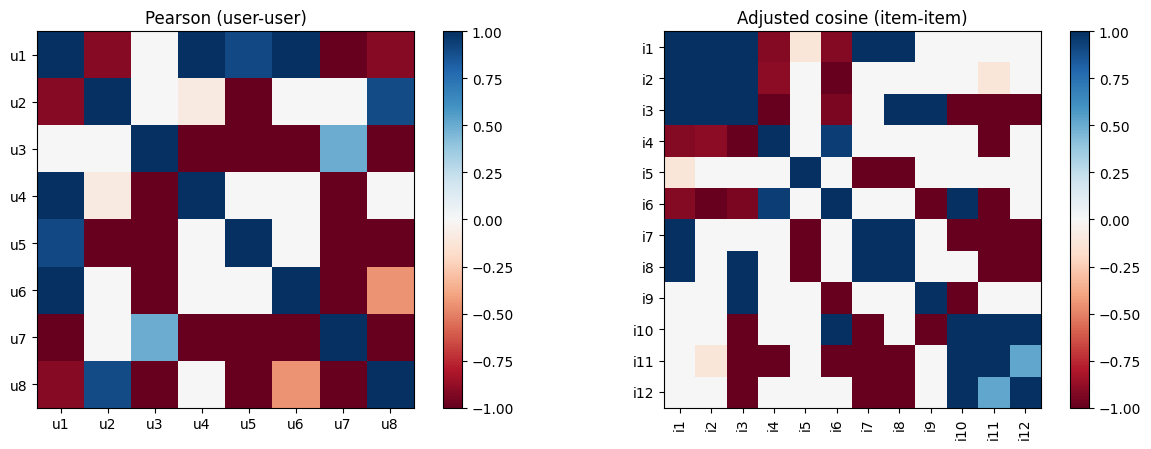

คะแนนทำนาย (rating models: 1–5) / คะแนนจัดอันดับ (Popularity, implicit models):


,i5 Wicked,i7 Ballerina,i8 Furiosa: A Mad Max Saga,i9 Conclave,i10 Dune: Part Two,i11 Mickey 17,i12 Project Hail Mary
GlobalMean,3.6250,3.6250,3.6250,3.6250,3.6250,3.6250,3.6250
UserMean,3.2000,3.2000,3.2000,3.2000,3.2000,3.2000,3.2000
ItemMean,3.0000,3.0000,3.5000,5.0000,3.5000,3.7500,4.5000
Popularity,2.0000,1.0000,1.0000,1.0000,1.0000,2.0000,2.0000
Baseline(bias),2.9440,3.0065,3.2565,3.7774,3.2565,3.4024,3.7565
User-kNN,1.8250,4.4500,4.4500,4.7000,1.7000,2.2000,3.2000
User-kNN+SigW,1.8250,4.4500,4.4500,4.7000,1.7000,2.2000,3.2000
Item-kNN,3.2000,5.0000,4.5000,4.0000,1.0000,3.2000,3.2000
User-kNN(implicit),0.4082,0.3333,0.3333,0.4082,0.0000,0.0000,0.0000
MF-SGD,2.7306,3.2287,3.4143,4.5138,2.6417,3.0997,3.8034


User-kNN เพื่อนบ้านที่ใช้: {'i5': 'u6(1.00), u4(1.00)', 'i7': 'u4(1.00)', 'i8': 'u4(1.00)', 'i9': 'u5(0.91)', 'i10': 'u5(0.91)', 'i11': 'u6(1.00)', 'i12': '— (ใช้ค่าเฉลี่ยผู้ใช้)'}
Item-kNN รายการคล้ายที่ใช้: {'i5': '— (ใช้ค่าเฉลี่ยผู้ใช้)', 'i7': 'i1(1.00)', 'i8': 'i3(1.00), i1(1.00)', 'i9': 'i3(1.00)', 'i10': 'i6(1.00)', 'i11': '— (ใช้ค่าเฉลี่ยผู้ใช้)', 'i12': '— (ใช้ค่าเฉลี่ยผู้ใช้)'}


In [4]:
u1 = U_INDEX[USERS[0]]
rows = []
for v in range(len(USERS)):
    if v == u1: continue
    s, n = pearson_users(R_FULL, u1, v)
    rows.append({"pair": f"{USERS[u1]}–{USERS[v]}", "n_co": n, "Pearson": s,
                 "SigWeight(β=3)": significance_weight(s, n, 3), "Shrink(λ=2)": shrink(s, n, 2),
                 "Cosine": cosine_users(R_FULL, u1, v), "Jaccard": jaccard_users(R_FULL, u1, v)})
display(pd.DataFrame(rows).round(4))

# ความคล้ายทุกคู่: Pearson ระหว่างผู้ใช้ และ Adjusted Cosine ระหว่างรายการ (ภาพที่ 5.4)
S_user = np.array([[pearson_users(R_FULL, a, b)[0] if a != b else 1 for b in range(len(USERS))] for a in range(len(USERS))])
S_item = np.array([[adjusted_cosine_items(R_FULL, a, b) if a != b else 1 for b in range(len(ITEMS))] for a in range(len(ITEMS))])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a_, M, lab, t in [(ax[0], S_user, USERS, "Pearson (user-user)"), (ax[1], S_item, ITEMS, "Adjusted cosine (item-item)")]:
    im = a_.imshow(M, cmap="RdBu", vmin=-1, vmax=1)
    a_.set_xticks(range(len(lab))); a_.set_xticklabels(lab, rotation=90 if len(lab) > 8 else 0)
    a_.set_yticks(range(len(lab))); a_.set_yticklabels(lab); a_.set_title(t)
    fig.colorbar(im, ax=a_, fraction=0.04)
plt.tight_layout(); plt.show()

# ค่าทำนาย/คะแนนของทุกโมเดลสำหรับรายการผู้สมัครของ u1
fitted_full = {m.name: m.fit(R_FULL) for m in make_models()}
cands_u1 = candidates_for(R_FULL, u1)
table = pd.DataFrame({name: [m.predict(u1, j) if m.rating_model else m.scores(u1)[j] for j in cands_u1]
                      for name, m in fitted_full.items()},
                     index=[f"{ITEMS[j]} {TITLE[ITEMS[j]]}" for j in cands_u1])
print("คะแนนทำนาย (rating models: 1–5) / คะแนนจัดอันดับ (Popularity, implicit models):")
display(table.round(4).T)
print("User-kNN เพื่อนบ้านที่ใช้:", {ITEMS[j]: fitted_full['User-kNN'].explain(u1, j) for j in cands_u1})
print("Item-kNN รายการคล้ายที่ใช้:", {ITEMS[j]: fitted_full['Item-kNN'].explain(u1, j) for j in cands_u1})
# สังเกต: User-kNN ให้ i9 Conclave อันดับหนึ่ง (u5 ชอบทั้ง The Wild Robot และ Conclave) — ระบบอิงเนื้อหาทำไม่ได้

## Part 4 — ออกแบบการทดลองแบบ Offline (หัวข้อ 5.14, 5.16)
**Protocol Card** ระบุทุกกติกาที่มีผลต่อตัวเลข เพื่อให้ทำซ้ำได้และเปรียบเทียบได้อย่างยุติธรรม

| ประเด็น | การทดลองที่ 1: Rating | การทดลองที่ 2: Ranking | Validation Split (Part 8) |
|---|---|---|---|
| คำถาม | ทำนายคะแนน 1–5 ได้ใกล้แค่ไหน | รายการที่ชอบจริงอยู่อันดับต้นหรือไม่ | ดูตัวอย่าง Output จริงของแต่ละโมเดล |
| การแบ่งข้อมูล | Leave-One-Rating-Out (32 ครั้ง) | Leave-One-Liked-Out (20 กรณี) | สุ่มกันคะแนน 25% ต่อผู้ใช้ (seed 42) |
| ฝึกใหม่ | ทุก fold | ทุก fold | ครั้งเดียวบนชุดฝึก |
| Candidate | — | Full Catalog: เรื่องที่ยังไม่มีคะแนน + เรื่องที่ซ่อน | เรื่องที่ไม่มีในชุดฝึก |
| Metric | RMSE, MAE (ตัดค่า 1–5) | P/R/F1/HR@3, MRR, MAP@3, nDCG@3, AUC | RMSE/MAE + P/R/nDCG@3 |
| คะแนนเสมอ | — | ค่าคาดหมาย (สมการ 5.14) + เรียงตามรหัส | สุ่มลำดับ (seed) |
| Beyond-Accuracy | — | Coverage, Gini, ILD, Novelty, Calibration, Personalization, ARP | — |

In [5]:
def leave_one_rating_out_folds(R):
    """แต่ละ fold ซ่อนคะแนน 1 ค่า → (u, i, ค่าจริง, R_train)"""
    folds = []
    for u, i in zip(*np.where(~np.isnan(R))):
        Rt = R.copy(); Rt[u, i] = np.nan; folds.append((u, i, R[u, i], Rt))
    return folds

def leave_one_liked_out_folds(R, min_likes=2):
    """เหมือนบทที่ 3–4: ผู้ใช้ที่ชอบ >= 2 เรื่อง ซ่อนเรื่องที่ชอบทีละเรื่อง"""
    folds = []
    for u in range(R.shape[0]):
        likes = [i for i in range(R.shape[1]) if not np.isnan(R[u, i]) and R[u, i] >= LIKE_T]
        if len(likes) < min_likes: continue
        for h in likes:
            Rt = R.copy(); Rt[u, h] = np.nan; folds.append((u, h, Rt))
    return folds

def validation_split(R, frac=0.25, seed=42):
    """สุ่มกันคะแนนต่อผู้ใช้ไว้เป็น Validation (อย่างน้อย 1 ค่า และเหลือในชุดฝึกอย่างน้อย 2 ค่า)"""
    rng = np.random.default_rng(seed); Rtr = R.copy(); val = []
    for u in range(R.shape[0]):
        rated = np.where(~np.isnan(R[u]))[0]
        n_val = min(max(1, int(round(frac * len(rated)))), max(len(rated) - 2, 0))
        for i in rng.choice(rated, size=n_val, replace=False):
            val.append((u, int(i), R[u, i])); Rtr[u, i] = np.nan
    return Rtr, pd.DataFrame(val, columns=["u", "i", "rating"])

RATING_FOLDS = leave_one_rating_out_folds(R_FULL)
RANK_FOLDS = leave_one_liked_out_folds(R_FULL)
R_TRAIN_VAL, VAL = validation_split(R_FULL, frac=0.25, seed=42)
print(f"Rating folds = {len(RATING_FOLDS)} | Ranking folds = {len(RANK_FOLDS)} | Validation ratings = {len(VAL)}")
display(VAL.assign(user=VAL.u.map(lambda x: USERS[x]), item=VAL.i.map(lambda x: f"{ITEMS[x]} {TITLE[ITEMS[x]]}"))[["user","item","rating"]])

Rating folds = 32 | Ranking folds = 20 | Validation ratings = 8


,user,item,rating
0,u1,i1 Toy Story 5,5.0
1,u2,i6 Bridget Jones: Mad About the Boy,5.0
2,u3,i11 Mickey 17,5.0
3,u4,i5 Wicked,1.0
4,u5,i6 Bridget Jones: Mad About the Boy,3.0
5,u6,i11 Mickey 17,3.0
6,u7,i3 The Wild Robot,3.0
7,u8,i6 Bridget Jones: Mad About the Boy,5.0


## Part 5 — การทดลองที่ 1: Rating Prediction (Leave-One-Rating-Out, หัวข้อ 5.14.1)
ซ่อนคะแนนทีละค่า ครบทั้ง 32 ค่า ฝึกใหม่ทุกครั้ง แล้วตัดค่าทำนายให้อยู่ใน 1–5 ก่อนคำนวณ RMSE และ MAE

In [6]:
def evaluate_rating(model_factory, folds=None):
    folds = folds or RATING_FOLDS; y, p = [], []
    for u, i, r, Rt in folds:
        m = model_factory().fit(Rt); y.append(r); p.append(m.predict(u, i))
    return {"RMSE": rmse(y, p), "MAE": mae(y, p)}, np.array(p)

t0 = time.time(); rating_rows = []; LOO_PRED = {}
for name in RATING_MODELS:
    res, preds = evaluate_rating(lambda name=name: get_model(name))
    rating_rows.append({"Model": name, "Family": get_model(name).family, **res}); LOO_PRED[name] = preds
rating_results = pd.DataFrame(rating_rows).sort_values("RMSE").reset_index(drop=True)
display(rating_results.round(4))
print(f"ใช้เวลา {time.time()-t0:.1f} s")
# สังเกต (ตารางที่ 5.16): ในวิธีที่บทเปรียบเทียบ GlobalMean ชนะทุกวิธีบนข้อมูล 32 คะแนน → ต้องเทียบกับระบบฐานที่ง่ายที่สุดเสมอ
# ALS (ไม่มี bias, λ=0.5) ที่เพิ่มใน Lab นี้เป็นตัวอย่างว่าการตั้งไฮเพอร์พารามิเตอร์/โครงสร้างโมเดลเปลี่ยนผลได้ — ข้อมูลเล็ก ผลจึงแกว่งง่าย

,Model,Family,RMSE,MAE
0,ALS,Latent factor,1.2712,0.9833
1,GlobalMean,Baseline,1.4541,1.2581
2,Item-kNN,Memory-based,1.6331,1.2969
3,UserMean,Baseline,1.8226,1.5625
4,User-kNN+SigW,Memory-based,1.8534,1.5234
5,User-kNN,Memory-based,1.8534,1.5234
6,Baseline(bias),Model-based,1.9531,1.7139
7,MF-SGD,Latent factor,1.9803,1.7105
8,ItemMean,Baseline,2.2006,1.9194


ใช้เวลา 11.4 s


## Part 6 — การทดลองที่ 2: Ranking (Leave-One-Liked-Out, หัวข้อ 5.14.2)
ทุกโมเดลถูกฝึกใหม่โดยไม่เห็นคะแนนที่ซ่อน แล้วจัดอันดับ Full Catalog
รายงาน **ค่าคาดหมายเมื่อคะแนนเสมอ** (สมการ 5.14) คู่กับแบบเรียงตามรหัส เพื่อแสดงว่ากติกาคะแนนเสมอเปลี่ยนผลได้

In [7]:
K = 3
def evaluate_ranking(model_factory, folds=None, k=K, seed=SEED):
    folds = folds or RANK_FOLDS; rng = np.random.default_rng(seed)
    rows, all_recs, lists = [], [], []
    for u, h, Rt in folds:
        m = model_factory().fit(Rt); sc = m.scores(u); cand = candidates_for(Rt, u)
        met = tie_aware_metrics(sc, cand, h, k)
        top = topk_random_tiebreak(sc, cand, k, rng); all_recs += top; lists.append(top)
        rows.append({"user": USERS[u], "heldout": ITEMS[h], **met,
                     "ILD": ild(top), "Novelty": novelty(top, Rt), "Calibration": calibration_genre(u, top, Rt),
                     "ARP": arp(top, Rt), "TopK": " | ".join(ITEMS[j] for j in top)})
    detail = pd.DataFrame(rows)
    summary = detail.select_dtypes(include=[np.number]).mean().to_dict()
    summary["tie cases"] = f"{int(detail['tie'].sum())}/{len(detail)}"
    summary["Coverage"] = coverage(all_recs); summary["Gini"] = gini_coefficient(all_recs)
    summary["Personalization"] = personalization(lists)
    return pd.Series(summary), detail

t0 = time.time(); rank_rows = []; RANK_DETAIL = {}
for name in MODEL_NAMES:
    s, d = evaluate_ranking(lambda name=name: get_model(name))
    rank_rows.append({"Model": name, "Family": get_model(name).family, **s.to_dict()}); RANK_DETAIL[name] = d
ranking_results = pd.DataFrame(rank_rows)
ACC_COLS = [f"HR@{K}", f"Precision@{K}", f"Recall@{K}", f"F1@{K}", "MRR", f"MAP@{K}", f"nDCG@{K}", "AUC"]
display(ranking_results[["Model", "Family"] + ACC_COLS + [f"HR@{K}(id-order)", "MRR(id-order)", "tie cases"]]
        .sort_values("MRR", ascending=False).round(4).reset_index(drop=True))
print(f"ใช้เวลา {time.time()-t0:.1f} s")
# สังเกต (ตารางที่ 5.17): User-kNN (HR@3 0.5662, MRR 0.5164) / Item-kNN / EASE นำ ส่วน MF, WRMF, BPR ซึ่งมีพารามิเตอร์มากกว่าข้อมูลทำได้แย่กว่า
# และคอลัมน์ id-order ต่างจากค่าคาดหมายมากในโมเดลที่มีคะแนนเสมอบ่อย
# (MF-SGD/BPR อาจต่างจากตารางในบทเล็กน้อยตาม λ จำนวนรอบ และลำดับการสุ่ม — ดู Part 10.2)

,Model,Family,HR@3,Precision@3,Recall@3,F1@3,MRR,MAP@3,nDCG@3,AUC,HR@3(id-order),MRR(id-order),tie cases
0,User-kNN,Memory-based,0.5662,0.1887,0.5662,0.2831,0.5164,0.4361,0.4692,0.6911,0.75,0.5621,10/20
1,User-kNN+SigW,Memory-based,0.5662,0.1887,0.5662,0.2831,0.5164,0.4361,0.4692,0.6911,0.75,0.5621,10/20
2,EASE,Implicit,0.4912,0.1638,0.4912,0.2456,0.5117,0.4239,0.4412,0.6437,0.60,0.5381,14/20
3,Item-kNN,Memory-based,0.5265,0.1755,0.5265,0.2633,0.4670,0.3832,0.4201,0.6538,0.65,0.4655,16/20
4,User-kNN(implicit),Memory-based,0.5089,0.1696,0.5089,0.2545,0.4620,0.3798,0.4131,0.6228,0.60,0.4577,18/20
5,ALS,Latent factor,0.5000,0.1667,0.5000,0.2500,0.4144,0.3125,0.3604,0.6749,0.50,0.4269,1/20
6,BPR,Implicit,0.4500,0.1500,0.4500,0.2250,0.3710,0.2667,0.3131,0.6282,0.45,0.3710,0/20
7,MF-SGD,Latent factor,0.4000,0.1333,0.4000,0.2000,0.3296,0.2417,0.2815,0.4872,0.40,0.3296,0/20
8,GlobalMean,Baseline,0.3362,0.1121,0.3362,0.1681,0.3160,0.2055,0.2388,0.5000,0.50,0.3883,20/20
9,UserMean,Baseline,0.3362,0.1121,0.3362,0.1681,0.3160,0.2055,0.2388,0.5000,0.50,0.3883,20/20


ใช้เวลา 19.3 s


## Part 7 — การทดลองที่ 3: Beyond-Accuracy
วัดจากรายการ Top-3 ของทุก fold (สุ่มลำดับรายการเสมอด้วย seed เดียวกัน)
- **Coverage**: สัดส่วนรายการในคลังที่เคยถูกแนะนำ · **Gini**: ความเหลื่อมล้ำของการถูกแนะนำ (ต่ำ = กระจาย)
- **ILD**: ความต่างของแนวภายในรายการ · **Novelty**: −log2(ความนิยม) · **Calibration**: สัดส่วนแนวตรงกับประวัติ
- **Personalization**: รายการของผู้ใช้ต่างกันแค่ไหน · **ARP**: ความนิยมเฉลี่ยของรายการที่แนะนำ

In [8]:
BEYOND_COLS = ["Coverage", "Gini", "ILD", "Novelty", "Calibration", "Personalization", "ARP"]
display(ranking_results[["Model", "Family"] + BEYOND_COLS].sort_values("Coverage", ascending=False).round(4).reset_index(drop=True))
# สังเกต: Popularity มี Coverage ต่ำ/Gini สูง/Novelty ต่ำ — ความแม่นยำกับความหลากหลายต้องดูคู่กัน

,Model,Family,Coverage,Gini,ILD,Novelty,Calibration,Personalization,ARP
0,GlobalMean,Baseline,1.0000,0.2000,0.7583,1.6786,0.4042,0.7474,2.6833
1,UserMean,Baseline,1.0000,0.2000,0.7583,1.6786,0.4042,0.7474,2.6833
2,User-kNN,Memory-based,1.0000,0.1694,0.7250,1.8368,0.4167,0.7649,2.4000
3,User-kNN(implicit),Memory-based,1.0000,0.1889,0.8083,1.7380,0.4500,0.7596,2.5667
4,Item-kNN,Memory-based,1.0000,0.2194,0.7417,1.8383,0.4375,0.7474,2.4167
5,User-kNN+SigW,Memory-based,1.0000,0.1694,0.7250,1.8368,0.4167,0.7649,2.4000
6,ALS,Latent factor,1.0000,0.1500,0.7917,1.8883,0.3854,0.7684,2.3333
7,WRMF,Implicit,1.0000,0.2472,0.7417,1.7839,0.4458,0.7386,2.5167
8,BPR,Implicit,1.0000,0.1194,0.7333,1.8160,0.4250,0.7772,2.4333
9,MF-SGD,Latent factor,1.0000,0.4944,0.7167,2.1261,0.4875,0.4895,2.0333


## Part 8 — ตัวอย่าง Output บน Validation Dataset: เทียบทุกโมเดล
ฝึกทุกโมเดลบน **ชุดฝึก** (R_TRAIN_VAL) ครั้งเดียว แล้วดู
1. **Rating**: ค่าทำนายของแต่ละโมเดลเทียบกับคะแนนจริงในชุด Validation
2. **Ranking**: Top-3 ของแต่ละโมเดล พร้อมเครื่องหมาย ✓ เมื่อแนะนำเรื่องที่ผู้ใช้ "ชอบ" ใน Validation

In [9]:
fitted_val = {m.name: m.fit(R_TRAIN_VAL) for m in make_models()}

# 8.1 Rating: ค่าทำนายเทียบค่าจริง
val_rating = VAL.copy()
val_rating.insert(0, "user", val_rating.u.map(lambda x: USERS[x]))
val_rating.insert(1, "movie", val_rating.i.map(lambda x: f"{ITEMS[x]} {TITLE[ITEMS[x]]}"))
for name in RATING_MODELS:
    val_rating[name] = [fitted_val[name].predict(u, i) for u, i in zip(VAL.u, VAL.i)]
print("8.1 Validation — Rating prediction (ค่าจริง vs ค่าทำนาย)")
display(val_rating.drop(columns=["u", "i"]).round(2))
val_rating_metrics = pd.DataFrame({name: {"RMSE": rmse(VAL.rating, val_rating[name]), "MAE": mae(VAL.rating, val_rating[name])}
                                   for name in RATING_MODELS}).T.sort_values("RMSE")
display(val_rating_metrics.round(4).T)

# 8.2 Ranking: Top-3 ของแต่ละโมเดล
rng_val = np.random.default_rng(SEED)
VAL_LIKED = VAL[VAL.rating >= LIKE_T].groupby("u")["i"].apply(set).to_dict()
rank_view, rank_metric_rows = [], []
for name, m in fitted_val.items():
    precs, recs_, ndcgs, all_top = [], [], [], []
    for u in range(len(USERS)):
        cand = candidates_for(R_TRAIN_VAL, u)
        top = topk_random_tiebreak(m.scores(u), cand, K, rng_val); all_top += top
        rel = VAL_LIKED.get(u, set())
        rank_view.append({"user": USERS[u], "model": name,
                          "Top-3": " | ".join(("✓" if j in rel else "") + ITEMS[j] for j in top)})
        if rel:
            precs.append(precision_at_k(top, rel, K)); recs_.append(recall_at_k(top, rel, K)); ndcgs.append(ndcg_at_k(top, rel, K))
    rank_metric_rows.append({"Model": name, f"P@{K}": np.mean(precs), f"R@{K}": np.mean(recs_), f"nDCG@{K}": np.mean(ndcgs),
                             "Coverage": coverage(all_top)})
print("8.2 Validation — Top-3 ต่อผู้ใช้ (✓ = เรื่องที่ผู้ใช้ชอบใน Validation)")
print("Validation liked:", {USERS[u]: [ITEMS[i] for i in s] for u, s in VAL_LIKED.items()})
display(pd.DataFrame(rank_view).pivot(index="model", columns="user", values="Top-3").loc[MODEL_NAMES])
display(pd.DataFrame(rank_metric_rows).sort_values(f"nDCG@{K}", ascending=False).round(4).reset_index(drop=True))

8.1 Validation — Rating prediction (ค่าจริง vs ค่าทำนาย)


,user,movie,rating,GlobalMean,UserMean,ItemMean,Baseline(bias),User-kNN,User-kNN+SigW,Item-kNN,MF-SGD,ALS
0,u1,i1 Toy Story 5,5.0,3.58,2.75,3.0,2.83,2.75,2.75,2.75,3.27,5.00
1,u2,i6 Bridget Jones: Mad About the Boy,5.0,3.58,3.67,1.0,2.82,3.67,3.67,5.00,3.45,4.92
2,u3,i11 Mickey 17,5.0,3.58,3.33,3.5,3.37,3.67,3.67,4.00,3.54,4.22
3,u4,i5 Wicked,1.0,3.58,4.67,4.0,4.57,5.00,5.00,4.67,4.45,3.20
4,u5,i6 Bridget Jones: Mad About the Boy,3.0,3.58,3.67,1.0,2.64,1.92,1.92,3.67,2.45,3.08
5,u6,i11 Mickey 17,3.0,3.58,4.50,3.5,3.89,4.50,4.50,4.50,4.15,3.94
6,u7,i3 The Wild Robot,3.0,3.58,3.67,4.0,3.77,3.67,3.67,3.67,3.94,3.23
7,u8,i6 Bridget Jones: Mad About the Boy,5.0,3.58,3.00,1.0,2.36,3.00,3.00,4.00,2.84,4.13


,ALS,GlobalMean,Item-kNN,MF-SGD,UserMean,User-kNN+SigW,User-kNN,Baseline(bias),ItemMean
RMSE,0.9446,1.4019,1.7192,1.8239,1.9430,2.0151,2.0151,2.0411,2.5617
MAE,0.6462,1.2500,1.3438,1.6238,1.7188,1.7708,1.7708,1.7750,2.2500


8.2 Validation — Top-3 ต่อผู้ใช้ (✓ = เรื่องที่ผู้ใช้ชอบใน Validation)
Validation liked: {'u1': ['i1'], 'u2': ['i6'], 'u3': ['i11'], 'u8': ['i6']}


user,u1,u2,u3,u4,u5,u6,u7,u8
model,,,,,,,,
GlobalMean,i9 | i8 | i11,i10 | i12 | ✓i6,✓i11 | i9 | i6,i11 | i9 | i4,i1 | i7 | i4,i1 | i7 | i8,i10 | i6 | i5,i8 | i10 | i9
UserMean,i5 | ✓i1 | i12,i2 | i12 | i11,i2 | i6 | i5,i4 | i3 | i5,i7 | i4 | i1,i1 | i12 | i6,i7 | i3 | i10,i8 | i10 | i9
ItemMean,i9 | i12 | i5,i9 | i12 | i2,i9 | i2 | i3,i9 | i12 | i2,i12 | i5 | i2,i9 | i12 | i3,i9 | i2 | i3,i9 | i12 | i3
Popularity,i5 | i12 | i7,i2 | i3 | i12,i5 | i2 | i4,i5 | i4 | i12,i4 | i2 | i12,i12 | i4 | i3,i5 | i4 | i2,i3 | i12 | i5
Baseline(bias),i9 | i12 | i5,i9 | i12 | i2,i9 | i2 | i3,i9 | i12 | i2,i12 | i2 | i5,i9 | i12 | i3,i9 | i2 | i5,i9 | i12 | i5
User-kNN,i9 | i8 | i7,i7 | i8 | i3,✓i11 | i2 | i3,i4 | i5 | i9,i2 | i1 | i12,i3 | i7 | i9,i10 | i6 | i2,i5 | i9 | i3
User-kNN+SigW,i9 | i12 | ✓i1,i7 | i8 | i11,✓i11 | i9 | i6,i5 | i4 | i9,i2 | i8 | i5,i3 | i10 | i11,i10 | i1 | i4,i5 | i7 | i9
Item-kNN,i9 | ✓i1 | i10,✓i6 | i9 | i12,✓i11 | i5 | i4,i3 | i4 | i2,i2 | i8 | i6,i3 | i12 | i7,i10 | i4 | i1,✓i6 | i5 | i8
User-kNN(implicit),i9 | i5 | i8,i2 | i8 | i11,✓i11 | i8 | i1,i11 | i2 | i10,i2 | i4 | i7,i3 | i4 | i1,i10 | i5 | i1,i5 | i7 | i1


,Model,P@3,R@3,nDCG@3,Coverage
0,Item-kNN,0.3333,1.00,0.9077,1.0000
1,ALS,0.2500,0.75,0.6577,1.0000
2,User-kNN+SigW,0.1667,0.50,0.3750,1.0000
3,EASE,0.1667,0.50,0.3750,0.6667
4,GlobalMean,0.1667,0.50,0.3750,0.8333
5,User-kNN,0.0833,0.25,0.2500,1.0000
6,WRMF,0.0833,0.25,0.2500,0.7500
7,User-kNN(implicit),0.0833,0.25,0.2500,0.8333
8,BPR,0.0833,0.25,0.2500,0.9167
9,UserMean,0.0833,0.25,0.1577,1.0000


## Part 9 — ตารางสรุปและ Chart: Accuracy + Beyond-Accuracy
รวมผลการทดลองที่ 1–3 ไว้ในตารางเดียว แล้วแสดงเป็นกราฟ

,Model,Family,HR@3,MRR,nDCG@3,AUC,Coverage,Gini,ILD,Novelty,Calibration,Personalization,ARP,RMSE,MAE
0,GlobalMean,Baseline,0.3362,0.3160,0.2388,0.5000,1.0000,0.2000,0.7583,1.6786,0.4042,0.7474,2.6833,1.4541,1.2581
1,UserMean,Baseline,0.3362,0.3160,0.2388,0.5000,1.0000,0.2000,0.7583,1.6786,0.4042,0.7474,2.6833,1.8226,1.5625
2,ItemMean,Baseline,0.1250,0.1931,0.0815,0.2757,0.5000,0.6778,0.7583,2.0550,0.5000,0.3123,2.1667,2.2006,1.9194
3,Popularity,Baseline,0.0000,0.1379,0.0000,0.1713,0.6667,0.4361,0.7167,1.4019,0.3667,0.6263,3.1000,NaN,NaN
4,Baseline(bias),Model-based,0.1250,0.1901,0.0783,0.2789,0.5000,0.6778,0.7583,2.0550,0.5000,0.3123,2.1667,1.9531,1.7139
5,User-kNN,Memory-based,0.5662,0.5164,0.4692,0.6911,1.0000,0.1694,0.7250,1.8368,0.4167,0.7649,2.4000,1.8534,1.5234
6,User-kNN+SigW,Memory-based,0.5662,0.5164,0.4692,0.6911,1.0000,0.1694,0.7250,1.8368,0.4167,0.7649,2.4000,1.8534,1.5234
7,Item-kNN,Memory-based,0.5265,0.4670,0.4201,0.6538,1.0000,0.2194,0.7417,1.8383,0.4375,0.7474,2.4167,1.6331,1.2969
8,User-kNN(implicit),Memory-based,0.5089,0.4620,0.4131,0.6228,1.0000,0.1889,0.8083,1.7380,0.4500,0.7596,2.5667,NaN,NaN
9,MF-SGD,Latent factor,0.4000,0.3296,0.2815,0.4872,1.0000,0.4944,0.7167,2.1261,0.4875,0.4895,2.0333,1.9803,1.7105


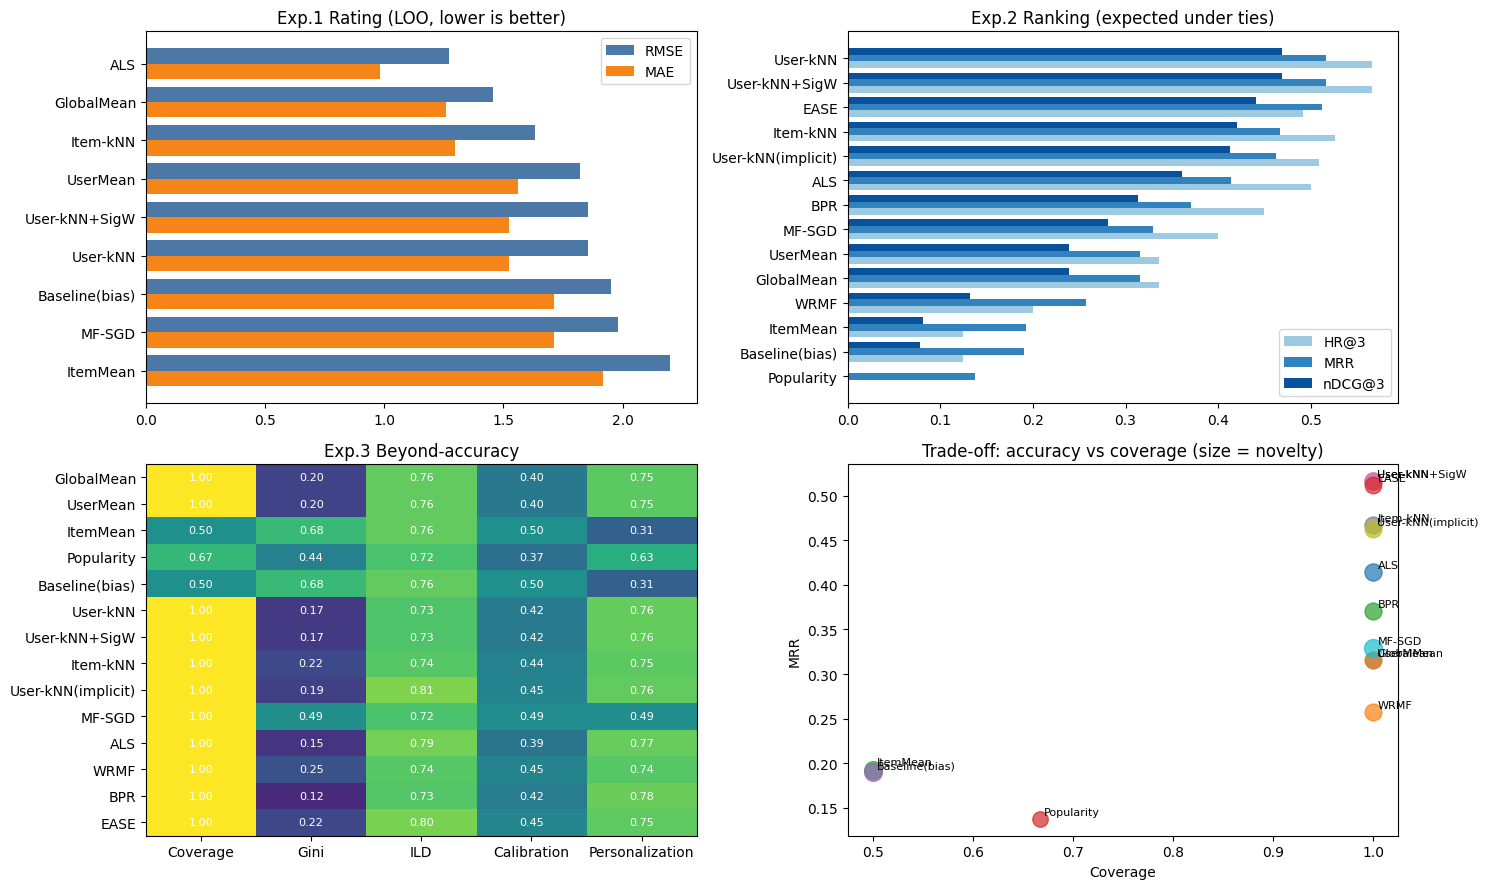

In [10]:
summary = ranking_results[["Model", "Family", f"HR@{K}", "MRR", f"nDCG@{K}", "AUC"] + BEYOND_COLS].merge(
    rating_results[["Model", "RMSE", "MAE"]], on="Model", how="left")
display(summary.round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
rr = rating_results.sort_values("RMSE"); yy = np.arange(len(rr))
axes[0, 0].barh(yy - 0.2, rr.RMSE, height=0.4, color="#4C78A8", label="RMSE")
axes[0, 0].barh(yy + 0.2, rr.MAE, height=0.4, color="#F58518", label="MAE")
axes[0, 0].set_yticks(yy); axes[0, 0].set_yticklabels(rr.Model)
axes[0, 0].invert_yaxis(); axes[0, 0].legend(); axes[0, 0].set_title("Exp.1 Rating (LOO, lower is better)")

rk = ranking_results.sort_values("MRR", ascending=True)
y = np.arange(len(rk)); w = 0.27
for n, (col, c) in enumerate([(f"HR@{K}", "#9ecae1"), ("MRR", "#3182bd"), (f"nDCG@{K}", "#08519c")]):
    axes[0, 1].barh(y + (n-1)*w, rk[col], height=w, color=c, label=col)
axes[0, 1].set_yticks(y); axes[0, 1].set_yticklabels(rk.Model); axes[0, 1].legend()
axes[0, 1].set_title("Exp.2 Ranking (expected under ties)")

bm = ranking_results.set_index("Model")[["Coverage", "Gini", "ILD", "Calibration", "Personalization"]]
im = axes[1, 0].imshow(bm.values, cmap="viridis", aspect="auto", vmin=0, vmax=1)
axes[1, 0].set_xticks(range(bm.shape[1])); axes[1, 0].set_xticklabels(bm.columns)
axes[1, 0].set_yticks(range(bm.shape[0])); axes[1, 0].set_yticklabels(bm.index)
for a in range(bm.shape[0]):
    for b in range(bm.shape[1]):
        axes[1, 0].text(b, a, f"{bm.values[a, b]:.2f}", ha="center", va="center", color="w", fontsize=8)
axes[1, 0].set_title("Exp.3 Beyond-accuracy")

for _, r in ranking_results.iterrows():
    axes[1, 1].scatter(r["Coverage"], r["MRR"], s=40 + 60*r["Novelty"], alpha=.7)
    axes[1, 1].annotate(r["Model"], (r["Coverage"], r["MRR"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1, 1].set_xlabel("Coverage"); axes[1, 1].set_ylabel("MRR"); axes[1, 1].set_title("Trade-off: accuracy vs coverage (size = novelty)")
plt.tight_layout(); plt.show()

## Part 10 — การทดลองเสริม
1. **Sensitivity ของไฮเพอร์พารามิเตอร์**: จำนวนเพื่อนบ้าน k ของ User/Item-kNN, λ ของ MF-SGD (ตารางที่ 5.12), λ ของ EASE
2. **ความแปรปรวนตามเมล็ดสุ่ม** ของ MF-SGD, WRMF, BPR (บทที่ 2: รายงานจากหลาย seed)
3. **Paired Bootstrap** ระดับผู้ใช้: ความต่างของ Reciprocal Rank ระหว่างสองโมเดลเชื่อได้เพียงใด

Model,EASE,Item-kNN,User-kNN
param,,,
k=1,NaN,0.467,0.5164
k=2,NaN,0.467,0.5164
k=3,NaN,0.467,0.5164
k=4,NaN,0.467,0.5164
k=5,NaN,0.467,0.5164
λ=1,0.5117,NaN,NaN
λ=20,0.5117,NaN,NaN
λ=5,0.5117,NaN,NaN
λ=50,0.5117,NaN,NaN


,λ,RMSE train,RMSE LOO,MAE LOO
0,0.02,0.0408,2.4472,2.1376
1,0.10,0.1658,2.3966,2.1232
2,0.50,0.5929,1.9803,1.7105


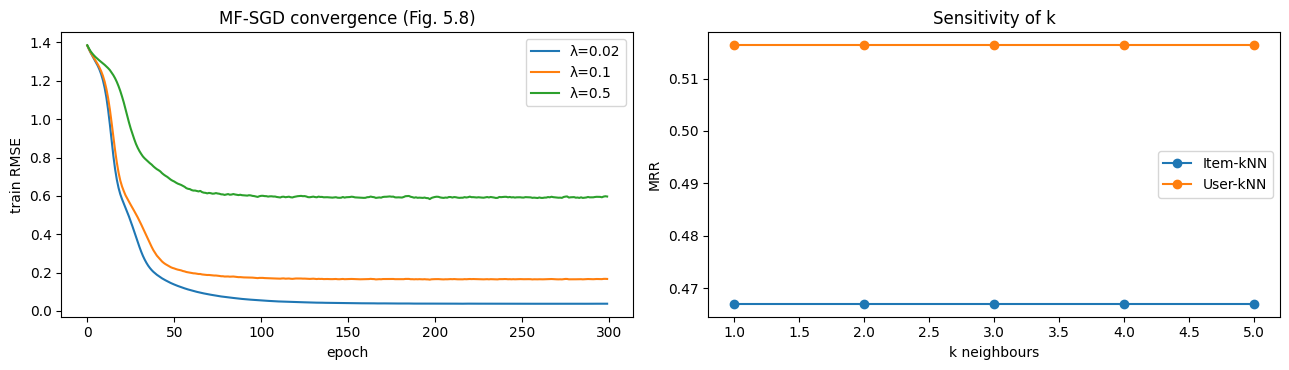

MRR          HR@3        
          mean     std  mean     std
Model                               
BPR     0.4218  0.0632  0.48  0.0570
MF-SGD  0.3293  0.0026  0.36  0.0652
WRMF    0.2855  0.0535  0.25  0.1000

User-kNN − EASE: mean ΔRR = -0.0030, 95% CI = [-0.0434, 0.0309] → CI คร่อมศูนย์: ยังสรุปไม่ได้ว่าต่างกันจริง
User-kNN − Item-kNN: mean ΔRR = 0.0344, 95% CI = [-0.0311, 0.1109] → CI คร่อมศูนย์: ยังสรุปไม่ได้ว่าต่างกันจริง
User-kNN − MF-SGD: mean ΔRR = 0.1927, 95% CI = [0.0611, 0.3131] → CI ไม่คร่อมศูนย์: ต่างอย่างมีหลักฐาน
User-kNN − Popularity: mean ΔRR = 0.3784, 95% CI = [0.1764, 0.5848] → CI ไม่คร่อมศูนย์: ต่างอย่างมีหลักฐาน


In [11]:
# 10.1 Sensitivity
sens = []
for k_ in [1, 2, 3, 4, 5]:
    for cls in [UserKNN, ItemKNN]:
        s, _ = evaluate_ranking(lambda: cls(k=k_))
        sens.append({"Model": cls.name, "param": f"k={k_}", "MRR": s["MRR"], f"HR@{K}": s[f"HR@{K}"]})
for lam in [1, 5, 20, 50]:
    s, _ = evaluate_ranking(lambda: EASE(lam=lam))
    sens.append({"Model": "EASE", "param": f"λ={lam}", "MRR": s["MRR"], f"HR@{K}": s[f"HR@{K}"]})
display(pd.DataFrame(sens).pivot(index="param", columns="Model", values="MRR").round(4))
# สังเกต: บน MovieMini-12 ค่า k แทบไม่มีผล เพราะแต่ละรายการมีเพื่อนบ้านเชิงบวกเพียง 1–2 ตัว
# และ λ ของ EASE เปลี่ยนขนาดคะแนนแต่ไม่เปลี่ยนลำดับในข้อมูลเล็กนี้ — บนข้อมูลจริง (LAB 2–3) ค่าเหล่านี้มีผลมาก

mf_rows = []
for reg in [0.02, 0.1, 0.5]:
    m = MF_SGD(k=2, reg=reg, epochs=150).fit(R_FULL)
    train_rmse = rmse([R_FULL[u, i] for u, i in zip(*np.where(known))], [m.predict(u, i) for u, i in zip(*np.where(known))])
    res, _ = evaluate_rating(lambda: MF_SGD(k=2, reg=reg, epochs=150))
    mf_rows.append({"λ": reg, "RMSE train": train_rmse, "RMSE LOO": res["RMSE"], "MAE LOO": res["MAE"]})
display(pd.DataFrame(mf_rows).round(4))   # ตารางที่ 5.12: λ เล็ก → train ดีขึ้นแต่ LOO แย่ลง = overfitting

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for reg in [0.02, 0.1, 0.5]:
    ax[0].plot(MF_SGD(k=2, reg=reg, epochs=300).fit(R_FULL).history, label=f"λ={reg}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train RMSE"); ax[0].legend(); ax[0].set_title("MF-SGD convergence (Fig. 5.8)")
sp = pd.DataFrame(sens); sp = sp[sp.Model != "EASE"]
for name, g in sp.groupby("Model"):
    ax[1].plot([int(p.split("=")[1]) for p in g.param], g.MRR, marker="o", label=name)
ax[1].set_xlabel("k neighbours"); ax[1].set_ylabel("MRR"); ax[1].legend(); ax[1].set_title("Sensitivity of k")
plt.tight_layout(); plt.show()

# 10.2 Seed variability
seed_rows = []
for seed in [1, 7, 42, 2569, 2026]:
    for cls in [MF_SGD, WRMF, BPR]:
        s, _ = evaluate_ranking(lambda: cls(seed=seed))
        seed_rows.append({"Model": cls.name, "seed": seed, "MRR": s["MRR"], f"HR@{K}": s[f"HR@{K}"]})
sd = pd.DataFrame(seed_rows)
display(sd.groupby("Model")[["MRR", f"HR@{K}"]].agg(["mean", "std"]).round(4))

# 10.3 Paired bootstrap ระดับผู้ใช้ (เหมือนหัวข้อ 5.14.2)
def paired_bootstrap(a_name, b_name, B=4000, seed=SEED):
    da = RANK_DETAIL[a_name].groupby("user")["MRR"].mean(); db = RANK_DETAIL[b_name].groupby("user")["MRR"].mean()
    diff = (da - db).values; rng = np.random.default_rng(seed)
    boots = [rng.choice(diff, size=len(diff), replace=True).mean() for _ in range(B)]
    return diff.mean(), np.percentile(boots, [2.5, 97.5])
best = ranking_results.sort_values("MRR", ascending=False).Model.tolist()[0]
for other in ["EASE", "Item-kNN", "MF-SGD", "Popularity"]:
    if other == best: continue
    m_, ci = paired_bootstrap(best, other)
    verdict = "→ CI คร่อมศูนย์: ยังสรุปไม่ได้ว่าต่างกันจริง" if ci[0] <= 0 <= ci[1] else "→ CI ไม่คร่อมศูนย์: ต่างอย่างมีหลักฐาน"
    print(f"{best} − {other}: mean ΔRR = {m_:.4f}, 95% CI = [{ci[0]:.4f}, {ci[1]:.4f}] {verdict}")
# สังเกต: ผู้ใช้มีเพียง 8 คน ช่วงความเชื่อมั่นจึงกว้าง — อย่าสรุปผู้ชนะจากค่าเฉลี่ยอย่างเดียว

## Part 11 — GUI: ข้อมูลผู้ใช้ + รายการแนะนำ + เทียบโมเดล
เลือกผู้ใช้และโมเดล → แสดง **ข้อมูลผู้ใช้** (สถิติ แนวที่ชอบ เพื่อนบ้านที่ใกล้ที่สุด), **ประวัติ**, **รายการแนะนำ** พร้อมคำอธิบาย
และ **ตารางเทียบ Top-K ของทุกโมเดล** สำหรับผู้ใช้คนเดียวกัน
โหมด "Validation" ฝึกบนชุดฝึก แล้วทำเครื่องหมาย ✓ ถ้าแนะนำเรื่องที่ซ่อนไว้และผู้ใช้ชอบ

In [12]:
import gradio as gr

def user_info_md(u, R):
    hist = np.where(~np.isnan(R[u]))[0]
    liked = [j for j in hist if R[u, j] >= LIKE_T]
    gcount = pd.Series([g for j in liked for g in GENRE[ITEMS[j]].split("|")]).value_counts()
    sims = sorted([(pearson_users(R, u, v)[0], USERS[v]) for v in range(len(USERS)) if v != u], reverse=True)[:3]
    return (f"### ผู้ใช้ {USERS[u]}\n"
            f"- จำนวนคะแนน: **{len(hist)}** · ค่าเฉลี่ย: **{np.nanmean(R[u]):.2f}** · ชอบ (≥4): **{len(liked)}** เรื่อง\n"
            f"- แนวที่ชอบ: {', '.join(f'{g} ({c})' for g, c in gcount.items()) or '-'}\n"
            f"- เพื่อนบ้านที่คล้ายที่สุด (Pearson): {', '.join(f'{n} ({s:.2f})' for s, n in sims)}")

def gui_recommend(user_id, model_name, k, mode):
    u = U_INDEX[user_id]; k = int(k)
    R = R_TRAIN_VAL if mode == "Validation (ฝึกบนชุดฝึก)" else R_FULL
    hidden = VAL[(VAL.u == u)] if R is R_TRAIN_VAL else VAL.iloc[0:0]
    hidden_like = set(hidden[hidden.rating >= LIKE_T].i)
    hist = pd.DataFrame([{"Movie": f"{ITEMS[j]} {TITLE[ITEMS[j]]}", "Genre": GENRE[ITEMS[j]], "Rating": R[u, j]}
                         for j in np.where(~np.isnan(R[u]))[0]]).sort_values("Rating", ascending=False)
    models = {m.name: m.fit(R) for m in make_models()}
    m = models[model_name]; cand = candidates_for(R, u); sc = m.scores(u)
    top = topk_random_tiebreak(sc, cand, k, np.random.default_rng(SEED))
    rec = pd.DataFrame([{"Rank": n, "Movie": f"{ITEMS[j]} {TITLE[ITEMS[j]]}", "Genre": GENRE[ITEMS[j]],
                         "Score": round(float(sc[j]), 4),
                         "Pred. rating": round(m.predict(u, j), 2) if m.rating_model else "-",
                         "Why": m.explain(u, j) if hasattr(m, "neighbors") else "",
                         "Hidden & liked": "✓" if j in hidden_like else ""} for n, j in enumerate(top, 1)])
    comp = pd.DataFrame({name: [("✓" if j in hidden_like else "") + f"{ITEMS[j]} {TITLE[ITEMS[j]]}"
                                for j in topk_random_tiebreak(mm.scores(u), cand, k, np.random.default_rng(SEED))]
                         for name, mm in models.items()}, index=[f"#{n}" for n in range(1, k+1)]).T.reset_index(names="Model")
    hid = (", ".join(f"{ITEMS[i]} {TITLE[ITEMS[i]]} (r={r:.0f})" for i, r in zip(hidden.i, hidden.rating))) or "-"
    return user_info_md(u, R) + f"\n- Validation ที่ซ่อนไว้: {hid}", hist, rec, comp

with gr.Blocks(title="Chapter 5 — Collaborative Filtering (MovieMini-12)") as demo:
    gr.Markdown("## Chapter 5 — Collaborative Filtering Recommender (MovieMini-12)")
    with gr.Row():
        dd_user = gr.Dropdown(USERS, value=USERS[0], label="User")
        dd_model = gr.Dropdown(MODEL_NAMES, value="User-kNN", label="Model")
        sl_k = gr.Slider(1, 6, 3, step=1, label="Top-K")
        rd_mode = gr.Radio(["Full data", "Validation (ฝึกบนชุดฝึก)"], value="Full data", label="Mode")
    btn = gr.Button("Recommend", variant="primary")
    md_user = gr.Markdown()
    with gr.Row():
        df_hist = gr.Dataframe(label="User History")
        df_rec = gr.Dataframe(label="Recommended Movies")
    df_comp = gr.Dataframe(label="Top-K ของทุกโมเดล (เทียบกัน)")
    btn.click(gui_recommend, [dd_user, dd_model, sl_k, rd_mode], [md_user, df_hist, df_rec, df_comp])
    demo.load(gui_recommend, [dd_user, dd_model, sl_k, rd_mode], [md_user, df_hist, df_rec, df_comp])

demo.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6a471c6af5b95e4488.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
